In [2]:
# %load_ext cuml.accel
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import confusion_matrix, classification_report
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [3]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [ ]:
import kagglehub

path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


In [5]:
data = pd.read_csv(path+'/bs140513_032310.csv')

In [6]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
data['customer'] = data['customer'].str[1:-1]
data['age'] = data['age'].str[1:-1]
data['gender'] = data['gender'].str[1:-1]
data['merchant'] = data['merchant'].str[1:-1]
data['category'] = data['category'].str.replace('es_', '')
data = data[data['gender'] != 'U']
data['age'] = data['age'].replace('U', '7')
data['age'] = data['age'].astype(float)

In [7]:
def create_amount_thresh(amount):
    if amount <= 500:
        return '0-500'
    elif amount <= 1000:
        return '500-1000'
    elif amount <= 1500:
        return '1000-1500'
    elif amount <= 2000:
        return '1500-2000'
    elif amount <= 2500:
        return '2000-2500'
    elif amount <= 3000:
        return '2500-3000'
    else:
        return '>3000'

In [8]:
data['amount_thresh'] = data['amount'].apply(create_amount_thresh)

In [9]:
customer = data.groupby('customer').size().reset_index(name='customer_total_trans')
customer['customer_ID'] = range(1, len(customer) + 1)

merchant = data.groupby('merchant').size().reset_index(name='merchant_total_trans')
merchant['merchant_ID'] = range(1, len(merchant) + 1)

category = data.groupby('category').size().reset_index(name='category_total_trans')
category['category_ID'] = range(1, len(category) + 1)

amount_thresh = data.groupby('amount_thresh').size().reset_index(name='amount_thresh_total_trans')
amount_thresh['amount_thresh_ID'] = range(1, len(amount_thresh) + 1)

In [10]:
data = data.merge(customer, on='customer').merge(merchant, on='merchant')
data = data.drop(['customer', 'merchant'], axis=1)
data = data.merge(category, on='category').merge(amount_thresh, on='amount_thresh')
data['category'] = data['category_ID']
data['amount_thresh'] = data['amount_thresh_ID']
data = data.drop(['category_ID', 'amount_thresh_ID'], axis=1)

In [11]:
age = data.groupby('age').size().reset_index(name='age_total_trans')
gender = data.groupby('gender').size().reset_index(name='gender_total_trans')
data = data.merge(age, on='age').merge(gender, on='gender')

In [12]:
total_freq = len(data)
data['merchant_total_trans'] = (data['merchant_total_trans'] / total_freq * 100).round(5)
data['category_total_trans'] = (data['category_total_trans'] / total_freq * 100).round(5)
data['amount_thresh_total_trans'] = (data['amount_thresh_total_trans'] / total_freq * 100).round(5)
data['age_total_trans'] = (data['age_total_trans'] / total_freq * 100).round(5)
data['gender_total_trans'] = (data['gender_total_trans'] / total_freq * 100).round(5)

In [13]:
data = data.drop('step', axis=1)
data = data[['fraud'] + [col for col in data.columns if col != 'fraud']]

In [14]:
data = pd.get_dummies(data, columns=['age', 'gender', 'category', 'amount_thresh'], drop_first=False)

In [15]:
data['fraud'] = data['fraud'].map({1: 'F', 0: 'NF'})

In [16]:
print("Data dimensions:", data.shape)

Data dimensions: (594128, 43)


In [17]:
pca_cols = ['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
            'gender_E', 'gender_F', 'gender_M',
            'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6', 'category_7',
            'category_8', 'category_9', 'category_10', 'category_11', 'category_12', 'category_13', 'category_14',
            'amount', 'amount_thresh_1', 'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
            'amount_thresh_6', 'amount_thresh_7']
scaler = StandardScaler()
pca_data_scaled = scaler.fit_transform(data[pca_cols])
pca = PCA(n_components=2)
pca_data = pca.fit_transform(pca_data_scaled)
pca_df = pd.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['fraud'] = data['fraud']

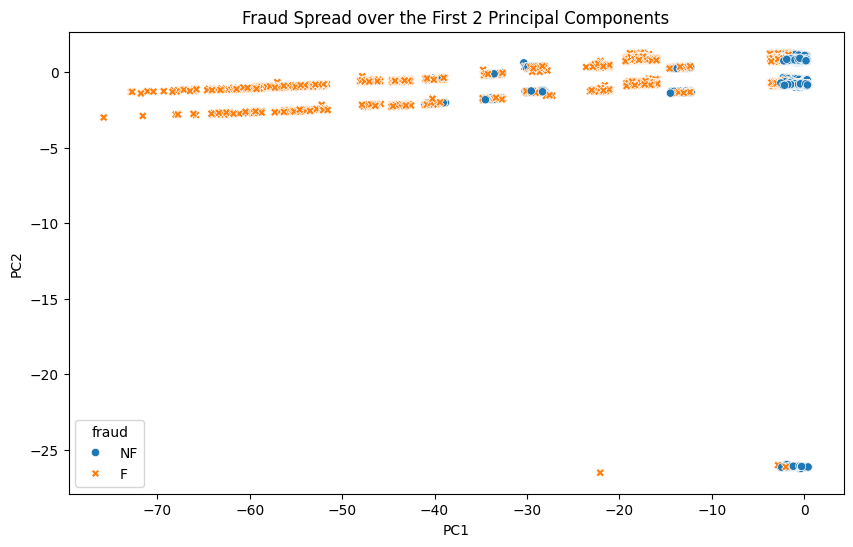

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', data=pca_df)
plt.title('Fraud Spread over the First 2 Principal Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In [19]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.09923016 0.06098442]


In [20]:
fraud_data = data[data['fraud'] == 'F']
non_fraud_data = data[data['fraud'] == 'NF']

In [21]:
non_fraud_sample = non_fraud_data.sample(frac=0.0166, random_state=123)  # Approx 9647 non-fraud samples
undersampling_data = pd.concat([non_fraud_sample, fraud_data]).sample(frac=1, random_state=123)
print("Undersampling data dimensions:", undersampling_data.shape)

Undersampling data dimensions: (16943, 43)


In [22]:
X = undersampling_data.drop('fraud', axis=1)
y = undersampling_data['fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

# Convert string labels to numerical labels
y_train = y_train.map({'F': 1, 'NF': 0})
y_test = y_test.map({'F': 1, 'NF': 0})

In [23]:
rf_model = RandomForestClassifier(random_state=123)
xgb_model = XGBClassifier(random_state=123, use_label_encoder=False, eval_metric='logloss')

In [24]:
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=123, ...)

In [25]:
rf_pred = rf_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

Random Forest Confusion Matrix:


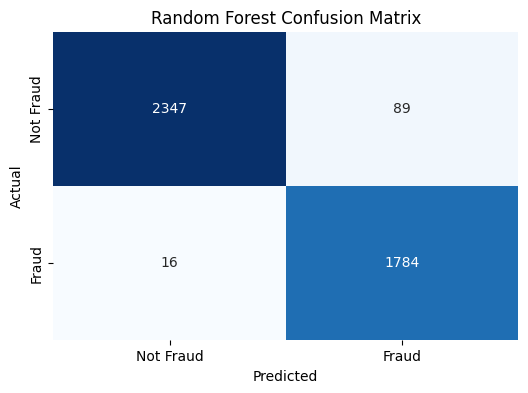

In [26]:
print("Random Forest Confusion Matrix:")
cm_rf = confusion_matrix(y_test, rf_pred, labels=[0, 1])
draw_confusion_matrix(cm_rf, title='Random Forest Confusion Matrix')

XGBoost Confusion Matrix:


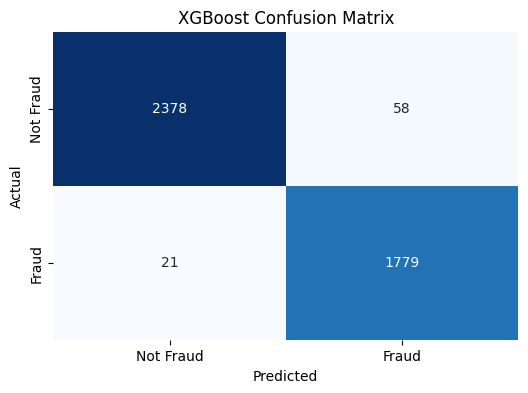

In [27]:
print("XGBoost Confusion Matrix:")
cm_xgb = confusion_matrix(y_test, xgb_pred, labels=[0,1])
draw_confusion_matrix(cm_xgb, title='XGBoost Confusion Matrix')

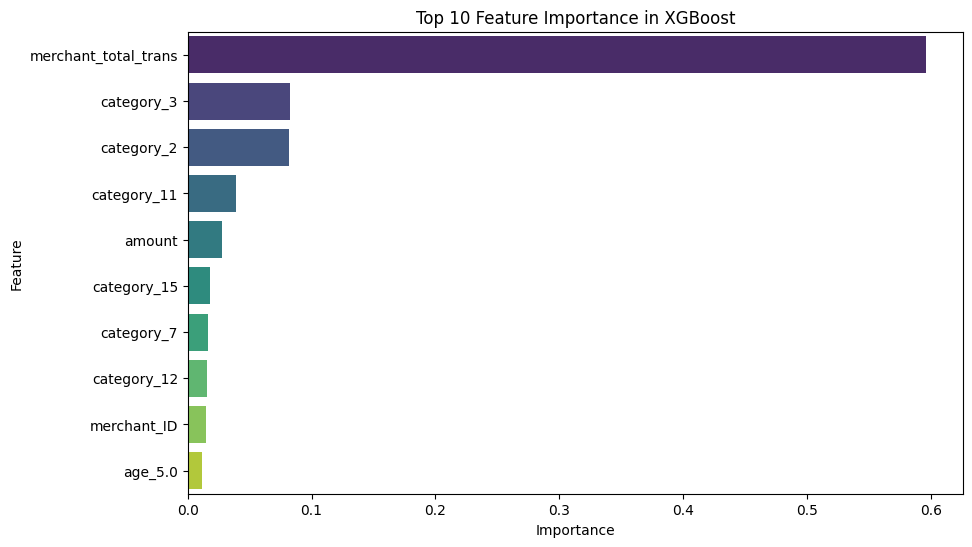

In [28]:
feature_importance = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)[:10]
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance.values, y=feature_importance.index, palette='viridis')
plt.title('Top 10 Feature Importance in XGBoost')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [29]:
ros = RandomOverSampler(sampling_strategy='auto', random_state=123)
X_ros, y_ros = ros.fit_resample(data.drop('fraud', axis=1), data['fraud'])

In [30]:
X_train_ros, X_test_ros, y_train_ros, y_test_ros = train_test_split(X_ros, y_ros, test_size=0.25, random_state=123, stratify=y_ros)

In [32]:
rf_model_ros = RandomForestClassifier(random_state=123)
xgb_model_ros = XGBClassifier(random_state=123, use_label_encoder=False, eval_metric='logloss')

# Convert string labels to numerical labels for oversampled data
y_train_ros = y_train_ros.map({'F': 1, 'NF': 0})
y_test_ros = y_test_ros.map({'F': 1, 'NF': 0})

rf_model_ros.fit(X_train_ros, y_train_ros)
xgb_model_ros.fit(X_train_ros, y_train_ros)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=123, ...)

In [33]:
rf_pred_ros = rf_model_ros.predict(X_test_ros)
xgb_pred_ros = xgb_model_ros.predict(X_test_ros)

Random Forest (Oversampled) Confusion Matrix:


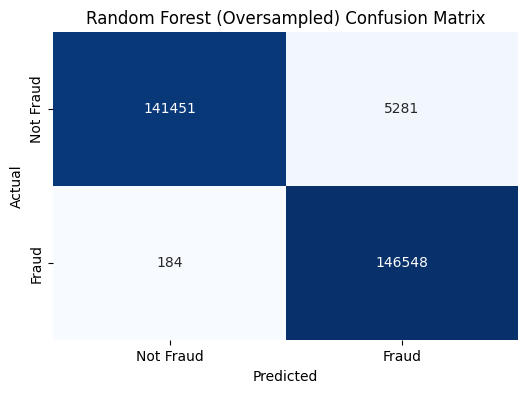

In [35]:
print("Random Forest (Oversampled) Confusion Matrix:")
cm_rf_ros = confusion_matrix(y_test_ros, rf_pred_ros, labels=[0,1])
draw_confusion_matrix(cm_rf_ros, title='Random Forest (Oversampled) Confusion Matrix')

XGBoost (Oversampled) Confusion Matrix:


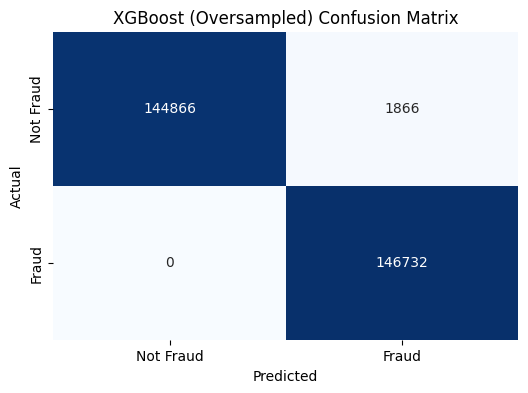

In [36]:
print("XGBoost (Oversampled) Confusion Matrix:")
cm_xgb_ros = confusion_matrix(y_test_ros, xgb_pred_ros, labels=[0,1])
draw_confusion_matrix(cm_xgb_ros, title='XGBoost (Oversampled) Confusion Matrix')

In [37]:
scaled_data_big = scaler.fit_transform(data[['amount', 'gender_E', 'gender_F', 'gender_M', 'age_0.0', 'age_1.0',
                                             'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
                                             'category_1', 'category_2', 'category_3', 'category_4', 'category_5',
                                             'category_6', 'category_7', 'category_8', 'category_9', 'category_10',
                                             'category_11', 'category_12', 'category_13', 'category_14',
                                             'merchant_total_trans', 'customer_total_trans', 'merchant_ID',
                                             'category_total_trans', 'customer_ID', 'amount_thresh_1',
                                             'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
                                             'amount_thresh_6', 'amount_thresh_7']])

In [38]:
kmeans = KMeans(n_clusters=3, random_state=123, n_init=25)
kmeans_labels = kmeans.fit_predict(scaled_data_big)
kmeans_data = pd.DataFrame(scaled_data_big, columns=['amount', 'gender_E', 'gender_F', 'gender_M', 'age_0.0', 'age_1.0',
                                                     'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
                                                     'category_1', 'category_2', 'category_3', 'category_4', 'category_5',
                                                     'category_6', 'category_7', 'category_8', 'category_9', 'category_10',
                                                     'category_11', 'category_12', 'category_13', 'category_14',
                                                     'merchant_total_trans', 'customer_total_trans', 'merchant_ID',
                                                     'category_total_trans', 'customer_ID', 'amount_thresh_1',
                                                     'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
                                                     'amount_thresh_6', 'amount_thresh_7'])
kmeans_data['cluster'] = kmeans_labels
kmeans_data['fraud'] = data['fraud']

In [39]:
print("K-means Cluster vs Fraud:")
print(pd.crosstab(kmeans_data['cluster'], kmeans_data['fraud']))

K-means Cluster vs Fraud:
fraud       F      NF
cluster              
0        6920  586928
1          58       0
2         222       0


In [40]:
pca_kmeans = PCA(n_components=3)
pca_kmeans_data = pca_kmeans.fit_transform(kmeans_data.drop(['cluster', 'fraud'], axis=1))
pca_kmeans_df = pd.DataFrame(pca_kmeans_data, columns=['PC1', 'PC2', 'PC3'])
pca_kmeans_df['cluster'] = kmeans_data['cluster']

In [41]:
fig = px.scatter_3d(pca_kmeans_df, x='PC1', y='PC2', z='PC3', color='cluster', title='K-means Clusters')
fig.update_traces(marker=dict(size=3))
fig.show()

In [42]:
distances = np.sqrt(((scaled_data_big - kmeans.cluster_centers_[kmeans_labels]) ** 2).sum(axis=1))
outliers = distances > np.percentile(distances, 95)  # Top 5% as outliers
kmeans_data_final = data.copy()
kmeans_data_final['cluster'] = kmeans_labels
kmeans_data_final['suspect_behaviour'] = np.where(outliers, 'F', 'NF')

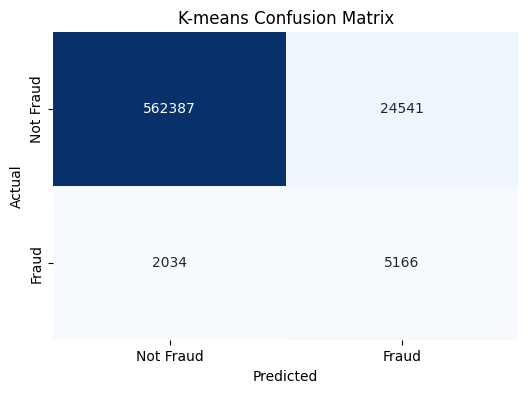

In [43]:
cm_kmeans = confusion_matrix(kmeans_data_final['fraud'], kmeans_data_final['suspect_behaviour'], labels=['NF', 'F'])
draw_confusion_matrix(cm_kmeans, title='K-means Confusion Matrix')

In [ ]:
dbscan = DBSCAN(eps=0.5, min_samples=10)
dbscan_labels = dbscan.fit_predict(scaled_data_big)
dbscan_data = pd.DataFrame(scaled_data_big, columns=['amount', 'gender_E', 'gender_F', 'gender_M', 'age_0.0', 'age_1.0',
                                                     'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
                                                     'category_1', 'category_2', 'category_3', 'category_4', 'category_5',
                                                     'category_6', 'category_7', 'category_8', 'category_9', 'category_10',
                                                     'category_11', 'category_12', 'category_13', 'category_14',
                                                     'merchant_total_trans', 'customer_total_trans', 'merchant_ID',
                                                     'category_total_trans', 'customer_ID', 'amount_thresh_1',
                                                     'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
                                                     'amount_thresh_6', 'amount_thresh_7'])
dbscan_data['cluster'] = dbscan_labels
dbscan_data_final = data.copy()
dbscan_data_final['dbscan_cluster'] = dbscan_labels
dbscan_data_final['unusual_behaviour'] = np.where(dbscan_data_final['dbscan_cluster'] == 0, 'F', 'NF')

[2025-07-04 06:19:48.263] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 4200 -> 3614. Using the larger integer type might result in better performance


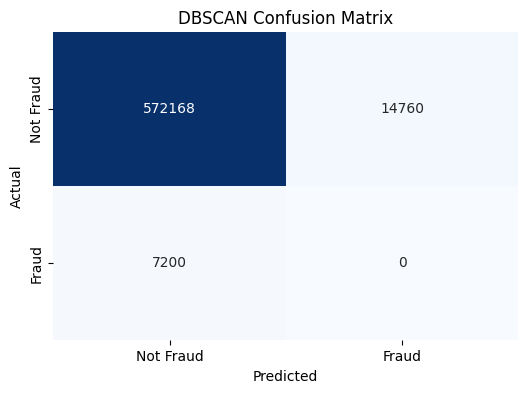

In [45]:
cm_dbscan = confusion_matrix(dbscan_data_final['fraud'], dbscan_data_final['unusual_behaviour'], labels=['NF', 'F'])
draw_confusion_matrix(cm_dbscan, title='DBSCAN Confusion Matrix')

In [46]:
print("Conclusion: K-means clustering identified three distinct groups:")
print("- Cluster 1: Non-suspect behavior (mostly non-fraud, low amounts, food/transport categories)")
print("- Cluster 2: Somewhat suspect behavior (mixed fraud/non-fraud, moderate amounts, wellness/fashion categories)")
print("- Cluster 3: Highly suspect behavior (mostly fraud, high amounts, leisure/travel categories)")

Conclusion: K-means clustering identified three distinct groups:
- Cluster 1: Non-suspect behavior (mostly non-fraud, low amounts, food/transport categories)
- Cluster 2: Somewhat suspect behavior (mixed fraud/non-fraud, moderate amounts, wellness/fashion categories)
- Cluster 3: Highly suspect behavior (mostly fraud, high amounts, leisure/travel categories)


In [47]:
import joblib

# Save KMeans model
joblib.dump(kmeans, 'kmeans_model.pkl')

# Save DBSCAN model
joblib.dump(dbscan, 'dbscan_model.pkl')

print("KMeans and DBSCAN models saved successfully.")

KMeans and DBSCAN models saved successfully.
